# Stage 5: Clustering (8 checkpoints)

**Stage:** 5 (training) · **Runs on:** Kaggle and locally (CPU)

Groups each dataset's texts by topic **without using labels**. Labels are used only afterwards,
to show which topics hold the most misinformation.

| Method | How it groups |
|---|---|
| K-Means | each text goes to the nearest of k centres |
| Gaussian Mixture | each cluster is a soft "cloud"; can also assign new texts, so validation and test parts get clusters too |

Input vectors: the 300 SVD numbers from Stage 4 (style numbers left out), scaled to length 1 so
distance reflects similar wording. The number of clusters k is chosen per dataset on the
training part with the elbow curve and the silhouette score.

| | |
|---|---|
| Input | Stage 2 split files, Stage 4 vectors and feature builders |
| Output | `kmeans__<dataset>.joblib`, `gmm__<dataset>.joblib`, `clusters__<dataset>.csv` (cluster of every row) for each dataset |

**On Kaggle:** attach the `misinfo_utils` utility script and add these notebooks as inputs (**Add Input → Your Work → Notebooks**): `02_split` and `04_features`.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("05")

misinfo_utils | stage 05 | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\05_models


In [2]:
import joblib, json
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

K_RANGE = range(2, 11)     # numbers of clusters tried
SILHOUETTE_SAMPLE = 5000   # silhouette is slow on large data, so it is measured on a sample
K_OVERRIDE = {}            # e.g. {"covid": 6} to fix k after looking at the curves


def svd_vectors(ds, split):
    X = mu.load_dense(ds, split)
    return normalize(X[:, :mu.load_builder(ds).n_svd])      # SVD part only, length 1

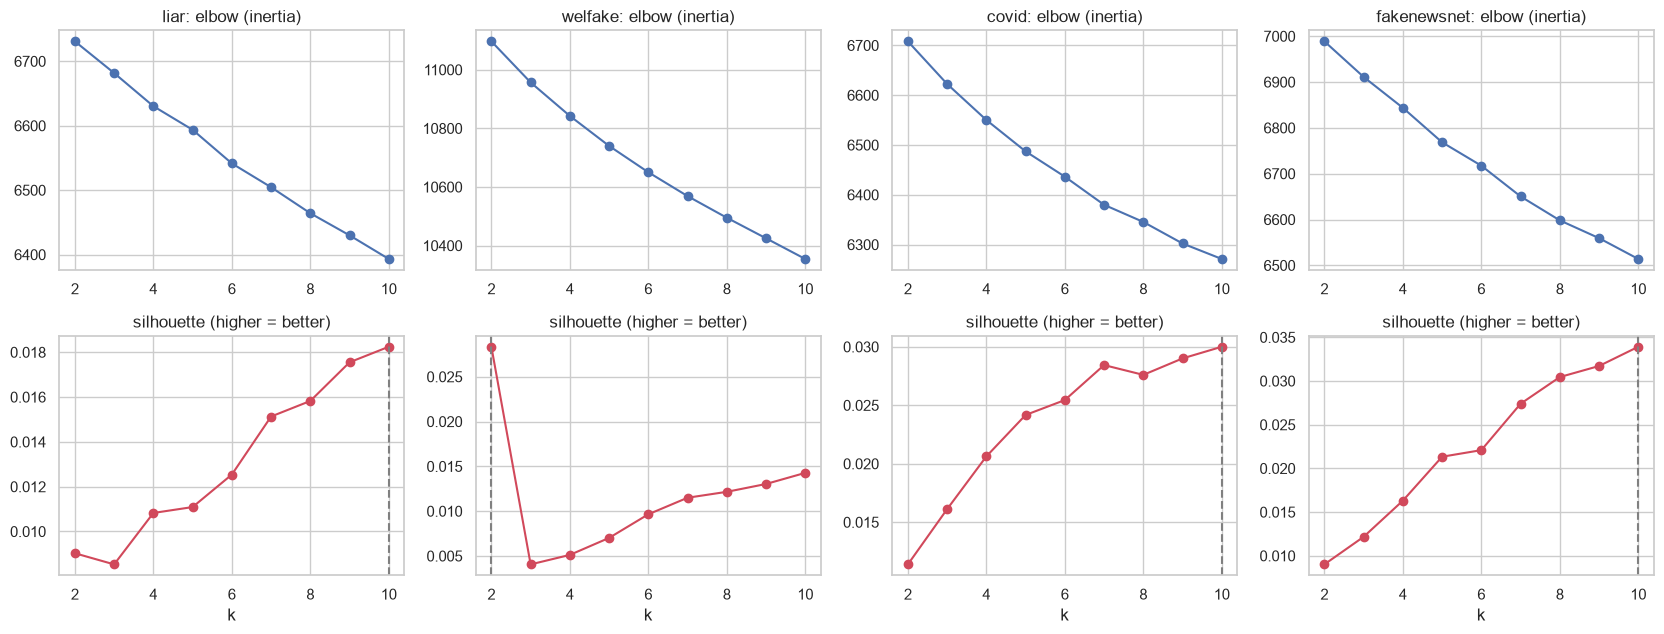

Chosen k: {'liar': 10, 'welfake': 2, 'covid': 10, 'fakenewsnet': 10}


In [3]:
curves, chosen_k = {}, {}
for ds in mu.DATASETS:
    X = svd_vectors(ds, "train")
    rows = []
    for k in K_RANGE:
        if k >= len(X):
            break
        km = KMeans(n_clusters=k, n_init=10, random_state=mu.SEED).fit(X)
        sil = silhouette_score(X, km.labels_, sample_size=min(SILHOUETTE_SAMPLE, len(X)), random_state=mu.SEED)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    curves[ds] = pd.DataFrame(rows)
    chosen_k[ds] = K_OVERRIDE.get(ds, int(curves[ds].loc[curves[ds]["silhouette"].idxmax(), "k"]))

fig, axes = plt.subplots(2, len(mu.DATASETS), figsize=(4.2 * len(mu.DATASETS), 6.5))
for i, ds in enumerate(mu.DATASETS):
    c = curves[ds]
    axes[0, i].plot(c["k"], c["inertia"], "o-"); axes[0, i].set_title(f"{ds}: elbow (inertia)")
    axes[1, i].plot(c["k"], c["silhouette"], "o-", color="#D1495B"); axes[1, i].set_title("silhouette (higher = better)")
    axes[1, i].axvline(chosen_k[ds], color="grey", ls="--"); axes[1, i].set_xlabel("k")
plt.tight_layout(); plt.show()
print("Chosen k:", chosen_k)

In [4]:
for ds in mu.DATASETS:
    k = chosen_k[ds]
    X_train = svd_vectors(ds, "train")
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=mu.SEED).fit(X_train)
    gmm = GaussianMixture(n_components=k, covariance_type="diag", random_state=mu.SEED).fit(X_train)
    joblib.dump(kmeans, mu.output_path(mu.checkpoint_file("kmeans", ds), subfolder=f"clustering/{ds}"))
    joblib.dump(gmm, mu.output_path(mu.checkpoint_file("gmm", ds), subfolder=f"clustering/{ds}"))

    parts = []
    for s in mu.SPLITS:
        X = svd_vectors(ds, s)
        parts.append(pd.DataFrame({"row_id": mu.load_split(ds, s)["row_id"], "split": s,
                                   "kmeans": kmeans.predict(X), "gmm": gmm.predict(X)}))
    pd.concat(parts).to_csv(mu.output_path(f"clusters__{ds}.csv", subfolder=f"clustering/{ds}"), index=False)

with open(mu.output_path("clustering_k.json", subfolder="clustering"), "w") as f:
    json.dump(chosen_k, f, indent=2)
print("Saved models and cluster assignments.")

Saved models and cluster assignments.


In [5]:
rows = []
for ds in mu.DATASETS:
    X = svd_vectors(ds, "train")
    labels = mu.load_split(ds, "train")["label"].values
    c = pd.read_csv(mu.output_path(f"clusters__{ds}.csv", subfolder=f"clustering/{ds}"))
    c = c[c["split"] == "train"]
    for method in ["kmeans", "gmm"]:
        assign = c[method].values
        sizes = pd.Series(assign).value_counts()
        rows.append({
            "dataset": ds, "method": method, "k": chosen_k[ds],
            "clusters used": len(sizes),                       # GMM can leave some clusters empty
            "largest cluster %": round(100 * sizes.max() / len(assign), 1),
            "silhouette": silhouette_score(X, assign, sample_size=min(SILHOUETTE_SAMPLE, len(X)),
                                           random_state=mu.SEED) if len(sizes) > 1 else float("nan"),
            # how far % misleading differs between clusters: higher = clusters separate fake/real better
            "spread of % misleading": round(pd.Series(labels).groupby(assign).mean().mul(100).std(), 1),
        })
    rows.append({"dataset": ds, "method": "agreement (ARI)",
                 "silhouette": adjusted_rand_score(c["kmeans"], c["gmm"])})

comparison = pd.DataFrame(rows)
display(comparison.round(3))

,dataset,method,k,clusters used,largest cluster %,silhouette,spread of % misleading
0,liar,kmeans,10.0,10.0,47.2,0.018,12.9
1,liar,gmm,10.0,10.0,17.6,0.001,7.9
2,liar,agreement (ARI),NaN,NaN,NaN,0.058,NaN
3,welfake,kmeans,2.0,2.0,53.3,0.028,27.4
4,welfake,gmm,2.0,2.0,71.5,-0.001,16.4
5,welfake,agreement (ARI),NaN,NaN,NaN,-0.000,NaN
6,covid,kmeans,10.0,10.0,32.1,0.030,39.6
7,covid,gmm,10.0,10.0,25.0,0.010,37.2
8,covid,agreement (ARI),NaN,NaN,NaN,0.339,NaN
9,fakenewsnet,kmeans,10.0,10.0,52.2,0.034,21.2


## Cluster profiles (training part)

Top words = the words with the highest average TF-IDF in the cluster. Name each cluster from
its words (e.g. "COVID testing numbers", "US elections") for the report.

In [6]:
for ds in mu.DATASETS:
    train = mu.load_split(ds, "train")
    clusters = pd.read_csv(mu.find_file(f"clusters__{ds}.csv")).query("split == 'train'")
    X_tfidf = mu.load_tfidf(ds, "train")
    vocab = mu.load_builder(ds).tfidf.get_feature_names_out()
    # skip terms made only of very common words ("the", "of the") so the topic shows
    useful = np.array([not set(t.split()) <= ENGLISH_STOP_WORDS for t in vocab])

    for method in ["kmeans", "gmm"]:
        rows = []
        for c in sorted(clusters[method].unique()):
            mask = (clusters[method] == c).values
            mean = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
            ranked = [i for i in np.argsort(mean)[::-1] if useful[i]][:6]
            rows.append({"cluster": c, "rows": int(mask.sum()),
                         "% misleading": round(100 * train.loc[mask, "label"].mean(), 1),
                         "top words": ", ".join(vocab[ranked])})
        print(f"===== {ds}: {method} (k = {chosen_k[ds]}) =====")
        display(pd.DataFrame(rows).set_index("cluster"))

===== liar: kmeans (k = 10) =====


,rows,% misleading,top words
cluster,,,
0,205,68.3,"voted, voted to, voted for, says, voted against, times"
1,412,39.6,"percent, percent of, 10 percent, says, 10, 40"
2,3357,59.5,"says, 000, tax, state, million, billion"
3,441,61.0,"says, said, governor, clinton, president, tax"
4,188,46.3,"united, united states, the united, states, states has, states is"
5,292,69.5,"care, health, health care, care law, the health, law"
6,786,57.0,"says, rate, tax, state, rate is, percent"
7,467,33.8,"year, 000, jobs, state, years, people"
8,233,68.2,"barack, barack obama, obama, president, president barack, says president"


===== liar: gmm (k = 10) =====


,rows,% misleading,top words
cluster,,,
0,167,53.3,"twice, twice as, says, as governor, governor, percent"
1,316,66.5,"says, donald, trump, donald trump, hillary clinton, clinton"
2,664,59.5,"says, rep, voting, campaign, gun, says she"
3,1128,48.9,"says, states, state, percent, texas, jobs"
4,573,61.4,"says, percent, clinton, percent of, state, hillary"
5,707,53.9,"care, obama, health, united states, states, united"
6,1161,58.1,"says, million, tax, state, billion, new"
7,764,42.4,"percent, percent of, 000, years, says, jobs"
8,380,69.2,"health, health care, care, obama, barack, president"


===== welfake: kmeans (k = 2) =====


,rows,% misleading,top words
cluster,,,
0,7463,27.4,"said, trump, president, state, government, said on"
1,6537,66.1,"trump, people, just, said, like, clinton"


... (6 outputs left out)

===== fakenewsnet: kmeans (k = 10) =====


,rows,% misleading,top words
cluster,,,
0,631,41.5,"new, set, on twitter, on instagram, taylor, trump"
1,241,78.8,"selena, gomez, selena gomez, bieber, justin bieber, justin"
2,285,80.0,"jennifer, aniston, jennifer aniston, jennifer lopez, lopez, affleck"
3,285,95.4,"brad, pitt, brad pitt, angelina, jolie, angelina jolie"
4,3784,41.8,"new, baby, 2018, trump, star, awards"
5,299,71.9,"jenner, kylie, kylie jenner, kendall, caitlyn, caitlyn jenner"
6,380,70.5,"kardashian, kim, kim kardashian, west, kanye, kanye west"
7,512,42.0,"trump, new, time, arrested, calls, for season"
8,216,69.9,"meghan, markle, meghan markle, harry, prince harry, prince"


===== fakenewsnet: gmm (k = 10) =====


,rows,% misleading,top words
cluster,,,
0,511,80.0,"jennifer, justin, kardashian, kim kardashian, net worth, net"
1,562,32.2,"united, congress, trump, america, united states, states"
2,837,35.7,"james, daughter, black, sexual, photo, rose"
3,1027,53.0,"kardashian, kim, new, meghan, jenner, markle"
4,808,66.3,"jenner, kardashian, kim, kim kardashian, kylie, scott"
5,809,43.5,"jessica, hadid, chris, jenner, red, 2018"
6,785,40.0,"williams, hollywood, love, tv, bachelor, jackson"
7,607,82.5,"jennifer, brad, pitt, brad pitt, justin, aniston"
8,1195,29.4,"star, season, 2018, obama, news, says"
